# Laboratorio de Recomendación — del carrusel "Para ti" a la decisión

Cierra el bloque de Venta Cruzada y Recomendación (la palanca del ARPU). Van a trabajar con una
base **completa**: 8,000 clientes de una cadena de cafeterías, ~10 meses de historial de compras y
un **experimento de 90 días**: a la mitad de los clientes, elegida al azar, la app les mostró un
carrusel **"Para ti"** con los 3 productos más populares que aún no habían comprado. La otra mitad
(control) no vio ningún carrusel.

Este laboratorio repite, sobre la base completa, lo que practicaron en los Breakout Rooms:

| Dónde lo vieron | Qué van a repetir aquí |
|---|---|
| Breakout 2 — La matriz y el coseno | La matriz cliente × producto y la similitud de coseno |
| Breakout 3 — Filtrado por ítem y por cliente | Los dos recomendadores colaborativos (el puntaje es una suma de similitudes) |
| Breakout 4 — Comparar y medir | Hit rate@3, precisión@3 y cobertura con un holdout |

**Los 5 pasos del laboratorio:**
1. Construyen los recomendadores (popularidad, por ítem, por cliente y **uno propio**).
2. Los evalúan con el holdout, **solo en el grupo control** (sin contaminación del carrusel).
3. Miden el **efecto real** del carrusel con el experimento: ΔARPU, margen neto y ΔCLV.
4. Deciden qué recomendador llevarían al siguiente experimento, cuidando a los clientes sin historial.
5. **La revelación**: el dataset trae información oculta (qué compras *ya iban a ocurrir* y cuáles las *causó* el carrusel) que en la vida real nunca existe. La destapan al final y comparan.

Donde dice **`# TODO`** hay algo para que ustedes completen.

> Los efectos de este conjunto de datos están **plantados** por el generador. Sirven para practicar el método;
> no prueban que ninguna cadena real obtenga estos resultados.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

warnings.filterwarnings("ignore")
VERDE, OSCURO, NARANJA, GRIS = "#00704A", "#11241C", "#C4512F", "#9A988E"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

catalogo = pd.read_csv("data/catalogo.csv")
hist = pd.read_csv("data/ordenes_historial.csv", parse_dates=["order_date"])
hold = pd.read_csv("data/ordenes_holdout.csv", parse_dates=["order_date"])
exp = pd.read_csv("data/experimento.csv")
clientes = pd.read_csv("data/clientes.csv")

print(f"{len(clientes):,} clientes · {len(hist):,} líneas de historial ({hist['order_date'].min().date()} a {hist['order_date'].max().date()})")
print(f"Experimento: {hold['order_date'].min().date()} a {hold['order_date'].max().date()} · "
      f"{(exp['grupo'] == 'tratamiento').sum():,} tratamiento · {(exp['grupo'] == 'control').sum():,} control")
exp.head()

8,000 clientes · 71,523 líneas de historial (2025-09-01 a 2026-06-30)
Experimento: 2026-07-01 a 2026-09-28 · 4,000 tratamiento · 4,000 control


,customer_id,grupo,mostrados
0,1,control,NaN
1,2,tratamiento,Chocolate Caliente|Té Chai|Galleta
2,3,tratamiento,Chocolate Caliente|Té Chai|Galleta
3,4,tratamiento,Chocolate Caliente|Té Chai|Té Verde
4,5,tratamiento,Chocolate Caliente|Té Chai|Galleta


## Paso 1 — construyan los recomendadores

Todos producen una matriz de **puntajes**: una fila por cliente, una columna por producto.
Nada de lo que pasó en el experimento se puede usar para construirlos: **solo el historial**.

Primero la matriz cliente × producto (la misma del Breakout 2).

In [2]:
productos = list(catalogo["item"])
col_agua = productos.index("Agua")

# TODO 1: la matriz cliente × producto (1 si compró al menos una vez en el historial, 0 si no).
# Pista: pd.crosstab(...) > 0, y .reindex(...) para que estén los 8,000 clientes y los 29 productos,
#        en el orden de `clientes` y de `productos`.
M = (
    (pd.crosstab(hist["customer_id"], hist["item"]) > 0)
    .astype(int)
    .reindex(
        index=clientes["customer_id"],
        columns=productos,
        fill_value=0
    )
)

X = M.values.astype(np.float32)
print(f"Matriz {X.shape[0]:,} × {X.shape[1]} · densidad {X.mean():.1%} · clientes sin historial: {(X.sum(axis=1) == 0).sum()}")

Matriz 8,000 × 29 · densidad 14.6% · clientes sin historial: 334


Dos piezas que ya vienen armadas: la **popularidad** (a todos lo mismo, lo más comprado) y la función `top_k`,
que se queda con los K productos de mayor puntaje **que el cliente aún no compró** (y sin Agua).

In [3]:
# Respaldo: popularidad (a todos lo mismo, lo más comprado)
S_pop = np.tile(X.sum(axis=0), (len(X), 1))

def top_k(scores, K=3):
    s = np.where(X > 0, -np.inf, scores).astype(np.float64)   # no recomendar lo ya comprado
    s[:, col_agua] = -np.inf                                   # ni el Agua
    return np.argsort(-s, axis=1)[:, :K]

**Filtrado por ítem** (Breakout 3): se compara **producto con producto** (las columnas de `X`), se calcula la
tabla de similitudes **una sola vez**, y el puntaje de cada cliente es la **suma de las similitudes** de cada
candidato con lo que el cliente ya compró.

In [4]:
# TODO 2: filtrado por ítem
S_it = cosine_similarity(X.T)         # la similitud de coseno entre las COLUMNAS de X  (productos × productos)
np.fill_diagonal(S_it, 0)
S_item = X @ S_it       # Suma de las similitudes con lo que el cliente ya compró (X @ ...)
print(S_it.shape, S_item.shape)

(29, 29) (8000, 29)


**Filtrado por cliente** (Breakout 3): se compara **cliente con cliente** (las filas de `X`). Para cada cliente se
buscan sus **K vecinos más parecidos** y el puntaje de cada producto es la suma de las similitudes de los vecinos
que **sí lo compraron** (cada vecino vota con su similitud).

In [5]:
K_VECINOS = 30
S_us = cosine_similarity(X)                   # (clientes × clientes)
np.fill_diagonal(S_us, 0)

S_user = np.zeros_like(X)
for i in range(len(X)):
    # TODO 3: los K vecinos más parecidos del cliente i, y sus compras ponderadas por la similitud
    vec = np.argsort(-S_us[i])[:K_VECINOS]             # posiciones de los K más parecidos (np.argsort)
    S_user[i] = S_us[i, vec] @ X[vec]       # similitudes de esos vecinos @ sus compras (X[vec])
print(S_us.shape, S_user.shape)

(8000, 8000) (8000, 29)


**Su propio recomendador.** El cuarto método lo eligen ustedes. Algunas ideas:
- **(a)** factorización con `TruncatedSVD(n_components=k)`: `Z = svd.fit_transform(X)` y `S_libre = Z @ svd.components_`
  (cada cliente y cada producto se resumen en unos pocos números "escondidos" de gusto);
- **(b)** el filtrado por cliente con otro K (10, 100, 300…);
- **(c)** un híbrido: mezcla de popularidad normalizada y filtrado por ítem;
- **(d)** cualquier otra idea suya (justifíquenla).

In [6]:
# TODO 4: SU modelo. Construyan una matriz de puntajes S_libre con la misma forma que X (8,000 × 29).
svd = TruncatedSVD(
    n_components=8,
    random_state=42
)

Z = svd.fit_transform(X)
S_libre = Z @ svd.components_

nombre_libre = "SVD (8 factores)"

assert isinstance(S_libre, np.ndarray) and S_libre.shape == X.shape, "Completen el TODO 4: S_libre debe tener la misma forma que X"
metodos = {"Popularidad": S_pop, "Filtrado por ítem": S_item, "Filtrado por cliente": S_user, nombre_libre: S_libre}
print("Métodos listos:", list(metodos))

Métodos listos: ['Popularidad', 'Filtrado por ítem', 'Filtrado por cliente', 'SVD (8 factores)']


## Paso 2 — evalúen con el holdout, pero SOLO en el grupo control

- **Entrenamiento** = el historial (de ahí salieron las matrices).
- **Holdout** = los 90 días del experimento. De ahí sale la respuesta: qué productos **nuevos** (que el cliente nunca
  había comprado) probó cada cliente.

**Regla del laboratorio:** el hit rate se mide **solo en el grupo control**. En los tratados, el carrusel influyó en lo
que compraron y ya no es una compra "limpia". En el control, un acierto es una compra que **ocurrió sin ninguna recomendación**.

In [7]:
H = (pd.crosstab(hold["customer_id"], hold["item"]) > 0).astype(int).reindex(index=M.index, columns=productos, fill_value=0).values
NUEVO = H * (1 - X); NUEVO[:, col_agua] = 0              # lo que probó en el holdout y NO había comprado antes (sin Agua)
elegibles = NUEVO.sum(axis=1) > 0
es_control = (exp.set_index("customer_id").loc[M.index, "grupo"] == "control").values

print(f"Clientes que probaron algo NUEVO en los 90 días:")
print(f"  control      : {(elegibles & es_control).sum():,} de {es_control.sum():,} ({elegibles[es_control].mean():.0%})")
print(f"  tratamiento  : {(elegibles & ~es_control).sum():,} de {(~es_control).sum():,} ({elegibles[~es_control].mean():.0%})")

Clientes que probaron algo NUEVO en los 90 días:
  control      : 1,797 de 4,000 (45%)
  tratamiento  : 2,297 de 4,000 (57%)


In [8]:
def hit_rate_at_k(scores, K=3, mask=None):
    top = top_k(scores, K)
    # TODO 5: ¿al menos una de las K recomendaciones fue un producto NUEVO que el cliente compró? (True/False por cliente)
    # Pista: NUEVO[u, top[u]] son los 1/0 de los K productos recomendados al cliente u.
    aciertos = np.array([
        NUEVO[u, top[u]].sum() > 0 
        for u in range(len(M))
    ])   # arreglo con un True/False por cliente
    
    return aciertos[mask].mean()

def precision_at_k(scores, K=3, mask=None):
    top = top_k(scores, K)
    return np.mean([NUEVO[u, top[u]].sum() / K for u in np.where(mask)[0]])

def cobertura(scores, K=3):
    return len(np.unique(top_k(scores, K)))

mask_eval = es_control & elegibles
res = pd.DataFrame({n: {"hit rate@3": hit_rate_at_k(s, mask=mask_eval),
                        "precisión@3": precision_at_k(s, mask=mask_eval),
                        "cobertura (de 28)": cobertura(s)} for n, s in metodos.items()}).T
res.round(3)

,hit rate@3,precisión@3,cobertura (de 28)
Popularidad,0.221,0.078,12.0
Filtrado por ítem,0.401,0.144,28.0
Filtrado por cliente,0.298,0.108,28.0
SVD (8 factores),0.369,0.132,28.0


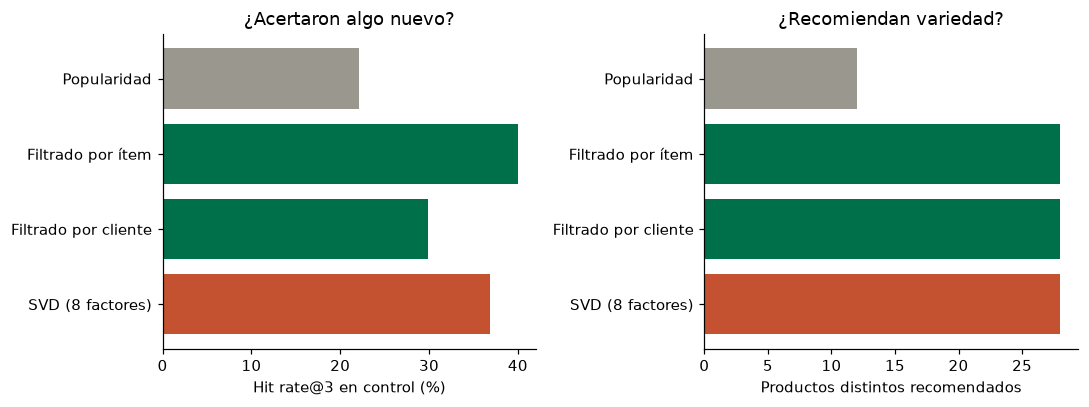

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
colores = [GRIS, VERDE, VERDE, NARANJA]
ax[0].barh(res.index[::-1], res["hit rate@3"][::-1] * 100, color=colores[::-1]); ax[0].set_xlabel("Hit rate@3 en control (%)"); ax[0].set_title("¿Acertaron algo nuevo?")
ax[1].barh(res.index[::-1], res["cobertura (de 28)"][::-1], color=colores[::-1]); ax[1].set_xlabel("Productos distintos recomendados"); ax[1].set_title("¿Recomiendan variedad?")
plt.tight_layout(); plt.show()

**Respondan aquí (2–3 líneas cada una):**
1. ¿Por qué evaluamos **solo en el grupo control**? ¿Qué pasaría con el hit rate si usáramos también a los tratados?
2. ¿Qué significa un "acierto" en el grupo control? ¿Fue *causado* por el recomendador?
3. ¿Qué método ganó y por cuánto sobre la popularidad? ¿Y en cobertura?

### Respuestas Paso 2

**1. ¿Por qué evaluamos solo en el grupo control? ¿Qué pasaría con el hit rate si usáramos también a los tratados?**

Evaluamos solo en el grupo control porque esos clientes no vieron el carrusel, por lo que sus compras reflejan su comportamiento natural y no están influenciadas por la recomendación. Si incluyéramos a los tratados, el hit rate podría aumentar artificialmente, porque algunos de los productos comprados pudieron haber sido impulsados por el propio carrusel. Eso contaminaría la evaluación del recomendador.

**2. ¿Qué significa un "acierto" en el grupo control? ¿Fue causado por el recomendador?**

Un acierto significa que al menos uno de los 3 productos recomendados fue realmente comprado por el cliente durante el holdout. Aún así, en el grupo control nadie recibió recomendaciones, por lo que ese acierto no fue causado por el recomendador. Solo significa que el modelo logró anticipar correctamente una compra que iba a ocurrir de forma natural.

**3. ¿Qué método ganó y por cuánto sobre la popularidad? ¿Y en cobertura?**

El mejor método fue el **Filtrado por ítem**, con un hit rate@3 de **0.401**, frente a **0.221** de Popularidad. Esto representa una mejora aproximada del:

(0.401 - 0.221) / 0.221 = 81.4%

Además, el filtrado por ítem tuvo cobertura completa de **28 productos**, mientras que Popularidad solo utilizó **12**. Por lo tanto, el filtrado por ítem no solo acertó más, sino que también generó recomendaciones mucho más variadas.

## Paso 3 — midan el efecto REAL del carrusel con el experimento

Aquí **sí** usan a los dos grupos. Como la asignación fue al azar, la diferencia entre tratamiento y control es el
efecto causal del carrusel (el que mostró los 3 productos más populares).

Primero el ingreso y el margen de cada cliente en los 90 días (con los precios y márgenes del catálogo).

In [10]:
precio = catalogo.set_index("item")["precio"]
margen = catalogo.set_index("item")["margen"]
hold["ingreso"] = hold["item"].map(precio)
hold["margen_usd"] = hold["ingreso"] * hold["item"].map(margen)
por_cliente = hold.groupby("customer_id")[["ingreso", "margen_usd"]].sum().reindex(clientes["customer_id"]).fillna(0)
ab = exp.set_index("customer_id").join(por_cliente)

trat = ab[ab["grupo"] == "tratamiento"]
ctrl = ab[ab["grupo"] == "control"]
print(f"ARPU de 90 días · control ${ctrl['ingreso'].mean():.2f} · tratamiento ${trat['ingreso'].mean():.2f}")
print(f"Un cliente de control gasta ${ctrl['ingreso'].mean():.2f} en promedio, con desviación estándar ${ctrl['ingreso'].std():.2f}")

ARPU de 90 días · control $15.74 · tratamiento $16.85
Un cliente de control gasta $15.74 en promedio, con desviación estándar $16.71


In [11]:
COSTO_CARRUSEL = 0.20   # US$ por cliente tratado en los 90 días (diseño, hosting y mantenimiento del carrusel)

# TODO 6: efecto del carrusel = diferencia de medias del ingreso (tratamiento − control) y su error estándar
#         error estándar = raíz( var_t / n_t + var_c / n_c );  IC 95% = diferencia ± 1.96 × error estándar
delta_arpu = (
    trat["ingreso"].mean()
    - ctrl["ingreso"].mean()
)

ee_arpu = np.sqrt(
    trat["ingreso"].var() / len(trat)
    + ctrl["ingreso"].var() / len(ctrl)
)
ic_arpu = (delta_arpu - 1.96 * ee_arpu, delta_arpu + 1.96 * ee_arpu)

delta_margen = trat["margen_usd"].mean() - ctrl["margen_usd"].mean()
ee_margen = np.sqrt(trat["margen_usd"].var() / len(trat) + ctrl["margen_usd"].var() / len(ctrl))
delta_margen_neto = delta_margen - COSTO_CARRUSEL
ic_margen_neto = (delta_margen_neto - 1.96 * ee_margen, delta_margen_neto + 1.96 * ee_margen)

print(f"ΔARPU (ingreso):  ${delta_arpu:+.2f} por cliente · IC 95% {ic_arpu[0]:+.2f} a {ic_arpu[1]:+.2f}")
print(f"Δmargen neto (después del costo del carrusel): ${delta_margen_neto:+.2f} por cliente · IC 95% {ic_margen_neto[0]:+.2f} a {ic_margen_neto[1]:+.2f}")

ΔARPU (ingreso):  $+1.11 por cliente · IC 95% +0.37 a +1.86
Δmargen neto (después del costo del carrusel): $+0.51 por cliente · IC 95% +0.05 a +0.98


Ahora conecten el ARPU con la fórmula de CLV de la clase:

**CLV = ARPU × margen × r / (1 + d − r) − CAC**

El carrusel solo mueve el **ARPU** (la palanca de esta semana). Supuestos dados, **trimestrales**: retención `r = 0.78` y
tasa de descuento `d = 0.03`.

In [12]:
R_TRIM, D_TRIM = 0.78, 0.03    # retención y tasa de descuento por trimestre (supuestos dados)

# TODO 7: factor de vida esperada = r / (1 + d − r)   y   ΔCLV por cliente = Δmargen neto × factor
#         (supuesto: el efecto del carrusel se mantiene mientras el cliente siga activo)
factor_vida = ( R_TRIM / (1 + D_TRIM - R_TRIM) )

delta_clv = ( delta_margen_neto * factor_vida )

print(f"Factor de vida esperada: {factor_vida:.2f} trimestres · ΔCLV por cliente ≈ ${delta_clv:+.2f}")
print(f"Para los {len(trat):,} clientes con carrusel: ${delta_clv * len(trat):+,.0f}")

Factor de vida esperada: 3.12 trimestres · ΔCLV por cliente ≈ $+1.60
Para los 4,000 clientes con carrusel: $+6,406


**Respondan aquí (2–3 líneas cada una):**
1. ¿El efecto del carrusel es estadísticamente distinto de cero? ¿Qué tan ancho es el intervalo y por qué (miren la desviación estándar del gasto)?
2. ¿Vale la pena el carrusel? Comparen el Δmargen con su costo y con el ΔCLV.
3. ¿Qué supuesto del ΔCLV es el más frágil?

## Respuestas Paso 3

### 1. ¿El efecto del carrusel es estadísticamente distinto de cero? ¿Qué tan ancho es el intervalo y por qué?

Sí. El ΔARPU estimado fue de **+\$1.11 por cliente**, con un intervalo de confianza al 95% de **+\$0.37 a +\$1.86**. Como todo el intervalo está por encima de cero, existe evidencia de un efecto positivo. El intervalo tiene un ancho aproximado de **\$1.49**, lo cual se explica porque existe bastante variabilidad en el gasto de los clientes: en el grupo control la desviación estándar fue de **\$16.71**, mucho mayor que el efecto promedio observado.

### 2. ¿Vale la pena el carrusel? Comparen el Δmargen con su costo y con el ΔCLV.

Sí. Después de descontar el costo de **\$0.20 por cliente**, el carrusel todavía genera un **margen incremental neto de +\$0.51 por cliente**, con un intervalo de confianza de **+\$0.05 a +\$0.98**. Además, si el efecto se mantiene durante la vida esperada del cliente, el incremento estimado de CLV es de aproximadamente **+\$1.60 por cliente**, equivalente a cerca de **+\$6,406 para los 4,000 clientes tratados**.

### 3. ¿Qué supuesto del ΔCLV es el más frágil?

El supuesto más frágil es considerar que el efecto incremental del carrusel se mantendrá durante toda la vida esperada del cliente.El experimento solo observa un período de 90 días, por lo que no sabemos si el aumento en margen continuará durante los siguientes trimestres con la misma intensidad. Por eso, el ΔCLV debe interpretarse como una proyección y no como un resultado observado directamente.

## Paso 4 — decidan qué llevarían al siguiente experimento

El carrusel del experimento mostró **popularidad**. Ustedes tienen mejores candidatos, pero **ninguno se probó con
un grupo de control**: solo tienen su hit rate en el grupo control (acierto ≠ causa). Primero revisen un problema
práctico: los clientes **sin historial** (arranque en frío).

In [13]:
n_prod = X.sum(axis=1)
tramos = pd.cut(n_prod, [-1, 0, 2, 5, 100], labels=["0 productos", "1–2", "3–5", "6+"])

filas = {}
for nombre in ["Popularidad", "Filtrado por ítem", "Filtrado por cliente"]:
    filas[nombre] = {t: hit_rate_at_k(metodos[nombre], mask=mask_eval & (tramos == t)) for t in tramos.categories}
tabla_frio = pd.DataFrame(filas).T
print("Clientes elegibles de control por tramo de historial:", {t: int((mask_eval & (tramos == t)).sum()) for t in tramos.categories})
tabla_frio.round(3)

Clientes elegibles de control por tramo de historial: {'0 productos': 98, '1–2': 285, '3–5': 790, '6+': 624}


,0 productos,1–2,3–5,6+
Popularidad,0.337,0.196,0.208,0.232
Filtrado por ítem,0.163,0.474,0.427,0.372
Filtrado por cliente,0.163,0.161,0.324,0.349


In [15]:
# TODO 8: recomendador FINAL = filtrado por ítem para quien tiene historial, y popularidad para quien no (arranque en frío)
tiene_historial = (X.sum(axis=1) > 0)[:, None]
S_final = np.where(
    tiene_historial,
    S_item,
    S_pop
)    # np.where(tiene_historial, <puntajes por ítem>, <puntajes de popularidad>)

metodos["Final (ítem + respaldo)"] = S_final
print("hit rate@3 en control · ítem solo:", round(hit_rate_at_k(S_item, mask=mask_eval), 3),
      "· final (ítem + respaldo):", round(hit_rate_at_k(S_final, mask=mask_eval), 3))

hit rate@3 en control · ítem solo: 0.401 · final (ítem + respaldo): 0.41


**Respondan aquí (una decisión defendida con sus números):**
1. ¿Qué recomendador llevarían al siguiente experimento? Consideren hit rate, **cobertura**, costo de calcularlo, **explicabilidad**
   ("porque compraste X") y qué pasa con los clientes sin historial.
2. Diseñen en tres líneas el experimento para medir el **ARPU incremental** de ese recomendador: grupos, métrica, duración
   y cómo evitarían el sesgo de novedad.

### Respuestas Paso 4

**1. ¿Qué recomendador llevarían al siguiente experimento?**

Llevaría al siguiente experimento el recomendador **Final (filtrado por ítem + respaldo de popularidad)**.

El filtrado por ítem fue el mejor método principal, con un **hit rate@3 de 0.401** y una cobertura de **28 de 28 productos**. Además, es más fácil de escalar que el filtrado por cliente y permite explicar las recomendaciones de forma sencilla, por ejemplo: “te recomendamos este producto porque compraste X”.

El análisis por historial también muestra por qué conviene agregar el respaldo de popularidad. Para clientes con **0 productos**, Popularidad obtuvo un hit rate de **0.337**, mientras que filtrado por ítem solo obtuvo **0.163**. En cambio, cuando ya existe historial, filtrado por ítem funciona mucho mejor: **0.474** para clientes con 1–2 productos, **0.427** para 3–5 y **0.372** para 6 o más.

Al combinar ambos métodos, el hit rate global en control aumenta de **0.401 a 0.410**, por lo que el modelo final resuelve mejor el problema de arranque en frío sin renunciar al buen desempeño del filtrado por ítem.

**2. Diseñen en tres líneas el experimento para medir el ARPU incremental de ese recomendador.**

Dividiría aleatoriamente a los clientes en un **grupo tratamiento**, que recibiría el carrusel con el recomendador final, y un **grupo control**, que no lo recibiría. Mediría durante **90 días** el ARPU, margen neto y tasa de compra de ambos grupos. El efecto incremental sería la diferencia entre tratamiento y control, verificando además si el resultado es estadísticamente significativo.

## La revelación final

Esta es la parte que no pudieron hacer con datos reales: los archivos `verdad_oculta_cliente_producto.csv` y
`verdad_oculta_clientes.csv` traen, para cada cliente y producto que aún no compró:

- `p_organica`: la probabilidad de que lo comprara **por cuenta propia** en los 90 días (sin ninguna recomendación);
- `p_incremental`: cuánto **sube** esa probabilidad **si se le muestra** en el carrusel.

En la vida real nadie conoce estas columnas. Compárenlas contra lo que midieron.

In [23]:
vo_cp = pd.read_csv("data/verdad_oculta_cliente_producto.csv")
vo_cl = pd.read_csv("data/verdad_oculta_clientes.csv").set_index("customer_id").loc[M.index]
pi = vo_cp.pivot(index="customer_id", columns="item", values="p_incremental").reindex(index=M.index, columns=productos).fillna(0).values
po = vo_cp.pivot(index="customer_id", columns="item", values="p_organica").reindex(index=M.index, columns=productos).fillna(0).values
precio_v = catalogo.set_index("item")["precio"].reindex(productos).values
n = len(X); filas_ = np.arange(n)[:, None]

filas = {}
for nombre, S in metodos.items():
    tk = top_k(S)
    inc = pi[filas_, tk].sum(axis=1)                       # compras EXTRA esperadas si se le muestran esos 3 productos
    inc_usd = (pi[filas_, tk] * precio_v[tk]).sum(axis=1)
    org = po[filas_, tk].sum(axis=1)                       # compras de esos 3 que YA iban a ocurrir
    filas[nombre] = {"hit rate@3 (control)": hit_rate_at_k(S, mask=mask_eval),
                     "ingreso incremental esperado (US$/cliente)": inc_usd.mean(),
                     "% de las compras que ya iban a ocurrir": org.sum() / (org.sum() + inc.sum())}
rev = pd.DataFrame(filas).T
rev.round(3)

,hit rate@3 (control),ingreso incremental esperado (US$/cliente),% de las compras que ya iban a ocurrir
Popularidad,0.221,0.998,0.307
Filtrado por ítem,0.401,1.191,0.438
Filtrado por cliente,0.298,1.186,0.376
SVD (8 factores),0.369,1.213,0.411
Final (ítem + respaldo),0.410,1.181,0.443


Efecto VERDADERO del carrusel (ingreso por cliente tratado): $0.99
Lo que midió su experimento (Paso 3): $+1.11 · IC 95% +0.37 a +1.86  →  ¿cae dentro?  True


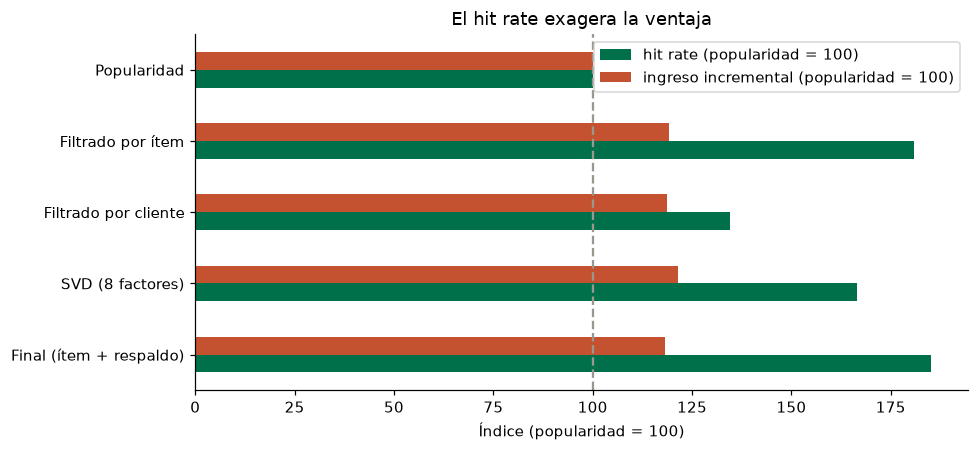

In [24]:
tk_pop = top_k(S_pop)
real_trat = (pi[filas_, tk_pop] * precio_v[tk_pop]).sum(axis=1)[~es_control].mean()
print(f"Efecto VERDADERO del carrusel (ingreso por cliente tratado): ${real_trat:.2f}")
print(f"Lo que midió su experimento (Paso 3): ${delta_arpu:+.2f} · IC 95% {ic_arpu[0]:+.2f} a {ic_arpu[1]:+.2f}  →  ¿cae dentro?  {ic_arpu[0] <= real_trat <= ic_arpu[1]}")

idx = pd.DataFrame({
    "hit rate (popularidad = 100)": rev["hit rate@3 (control)"] / rev.loc["Popularidad", "hit rate@3 (control)"] * 100,
    "ingreso incremental (popularidad = 100)": rev["ingreso incremental esperado (US$/cliente)"] / rev.loc["Popularidad", "ingreso incremental esperado (US$/cliente)"] * 100,
})
ax = idx.iloc[::-1].plot.barh(color=[VERDE, NARANJA], figsize=(9, 4.2))
ax.axvline(100, color=GRIS, linestyle="--"); ax.set_xlabel("Índice (popularidad = 100)"); ax.set_title("El hit rate exagera la ventaja")
plt.tight_layout(); plt.show()

In [25]:
# ¿A todos hay que mostrarles el carrusel? El efecto depende de qué tan receptivo es cada cliente (columna oculta)
cuartil = pd.qcut(vo_cl["receptividad"], 4, labels=["Q1 (menos receptivos)", "Q2", "Q3", "Q4 (más receptivos)"])
tk = top_k(S_item)
inc_usd_item = (pi[filas_, tk] * precio_v[tk]).sum(axis=1)
pd.Series(inc_usd_item).groupby(cuartil.values).mean().round(2).rename("ingreso incremental esperado (US$/cliente) · filtrado por ítem")

Q1 (menos receptivos)    0.47
Q2                       0.94
Q3                       1.38
Q4 (más receptivos)      1.98
Name: ingreso incremental esperado (US$/cliente) · filtrado por ítem, dtype: float64

**Respondan aquí (2–3 líneas cada una):**
1. ¿Cae el efecto verdadero dentro del intervalo que midió su experimento?
2. Comparen el **hit rate** con el **ingreso incremental** de cada método. ¿La ventaja del filtrado por ítem sobre la popularidad es igual de grande en las dos medidas? ¿Por qué?
3. ¿Qué porcentaje de las compras "acertadas" **ya iban a ocurrir**? ¿Qué significa para el ARPU que reportaría un directivo si solo mirara el hit rate?
4. Según los cuartiles de receptividad: ¿a todos los clientes hay que mostrarles el carrusel? ¿Qué técnica de la Semana 3 ayudaría a decidir a quién?

### Respuestas de la revelación final

**1. ¿Cae el efecto verdadero dentro del intervalo que midió su experimento?**

Sí. El efecto verdadero fue de **\$0.99 por cliente tratado**, mientras que el experimento estimó **+\$1.11**, con un IC 95% de **+\$0.37 a +\$1.86**. Por lo tanto, el valor verdadero sí cae dentro del intervalo y la estimación experimental estuvo bastante cerca.

**2. Comparen el hit rate con el ingreso incremental de cada método. ¿La ventaja del filtrado por ítem sobre la popularidad es igual de grande en las dos medidas? ¿Por qué?**

No. El filtrado por ítem mejora el hit rate de **0.221 a 0.401**, aproximadamente **81%**, pero el ingreso incremental solo aumenta de **\$0.998 a \$1.191**, cerca de **19%**. Esto ocurre porque acertar una compra no significa necesariamente haberla causado; muchas compras habrían ocurrido incluso sin la recomendación.

**3. ¿Qué porcentaje de las compras "acertadas" ya iban a ocurrir? ¿Qué significa para el ARPU que reportaría un directivo si solo mirara el hit rate?**

En filtrado por ítem, **43.8%** de las compras acertadas ya iban a ocurrir; en Popularidad fue **30.7%**, Cliente-based **37.6%**, SVD **41.1%** y el modelo final **44.3%**. Si un directivo mirara solo el hit rate, podría sobreestimar el impacto sobre el ARPU al atribuir al recomendador ventas que en realidad eran orgánicas.

**4. Según los cuartiles de receptividad: ¿a todos los clientes hay que mostrarles el carrusel? ¿Qué técnica de la Semana 3 ayudaría a decidir a quién?**

No necesariamente. El ingreso incremental va de **\$0.47** en el cuartil menos receptivo hasta **\$1.98** en el más receptivo, por lo que el efecto cambia mucho entre clientes. La técnica de **uplift modeling** de la Semana 3, por ejemplo un **T-Learner**, ayudaría a identificar a quién mostrarle el carrusel según su efecto incremental esperado.

## Para entregar

1. El notebook completo, **ejecutado de principio a fin**, con sus respuestas a las preguntas de cada paso.
2. **Su propia app de Streamlit** (usen `streamlit_starter.py` como punto de partida) que le permita a alguien de
   negocio explorar los recomendadores: elegir un cliente y un método, ver sus **3 recomendaciones con el "porque"**, y la
   tabla de comparación (hit rate y cobertura) — con al menos un control interactivo (slider o selector).
3. Una conclusión de una página para el Presidente de Marketing: ¿qué recomendador llevarían al siguiente experimento,
   cuánto vale (ΔARPU y ΔCLV) y qué tan cerca estuvo el hit rate de la verdad?